<a href="https://colab.research.google.com/github/eeswepe/PCVK_GANJIL_2026/blob/main/week2/Week2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## D. PRAKTIKUM

D1. Pengenalan Python: Pengolahan Citra Dasar dan memahami channel warna pada OpenCV dan
konversinya

### 1. Membuat koneksi antara Colab dengan Google Drive agar bisa mengakses file di dalamnya

Menggunakan file yang sama dengan praktikum pada D2, import folder yang ada di Drive Anda.
Setelah kode dijalankan, akan muncul pop up untuk terhubung ke Google Drive. Jika berhasil,
Google Colab sudah dapat mengakses folder gdrive Anda dengan keterangan output program
"Mounted at /content/drive".

Cara yang kedua dengan mengklik tombol folder di sebelah kiri, pilih tombol gdrive, lalu
Connect to Google Drive. Pilih folder dan klik icon titik 3 di sebelah kanan file gambar yang
akan digunakan, klik copy path, dan gunakan path tersebut pada code berikutnya.

Jika posisi gambar tersimpan di computer local/laptop, cara aksesnya bisa menggunakan fungsi
upload gambar. Jika Choose Files di klik, akan muncul direktori dari computer local. Setelah
dipilih gambar yang akan ditampilkan atau diolah, gambar tersimpan di google colab.

In [11]:
import cv2 as cv
from google.colab.patches import cv2_imshow
from skimage import io
import matplotlib.pyplot as plt
import numpy as np

In [12]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
#from google.colab import files
#uploaded = files.upload()

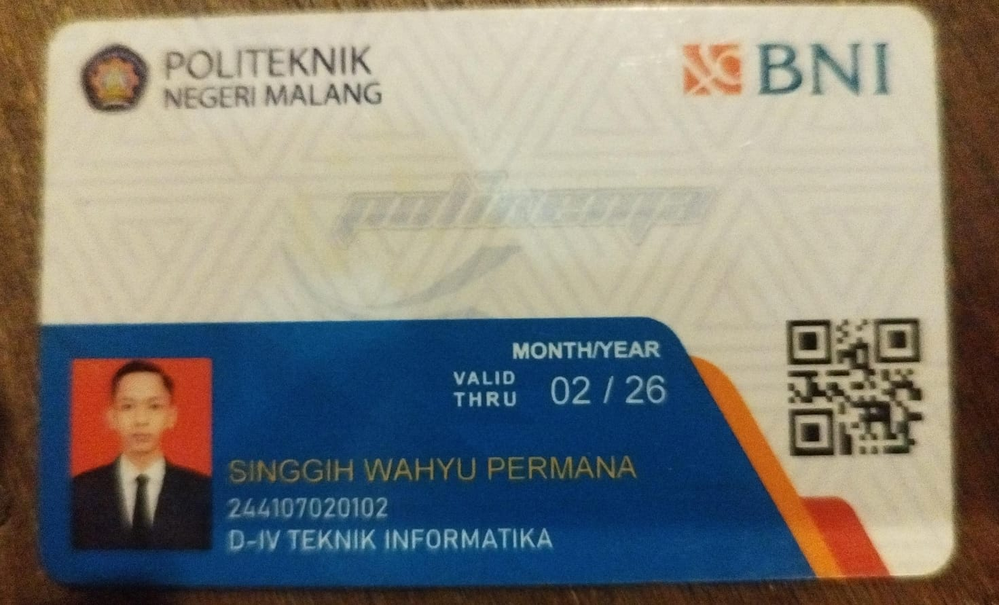

Resolusi gambar:  1471  x  891


In [14]:
img = cv.imread('/content/drive/MyDrive/pcvk/week2/ktm.jpeg')
cv2_imshow(img)
print("Resolusi gambar: ", img.shape[1], " x ", img.shape[0])

### 2. Menampilkan Gambar

Untuk menampilkan Gambar, bisa menampilkan langsung (Image Display) salah satunya menggunakan
library openCV dengan fungsi `cv2.imshow()` atau `cv2_imshow()` di Google Colab atau menampilkan
dalam Plot (Image Plotting) menggunakan library Matplotlib (`plt.imshow`). Berikut ini cara
menampilkan gambar dalam Plot supaya bisa diketahui ukuran lebar dan Panjang dari Image.

Hasilnya berupa output gambar yang sudah di plot dengan matplotlib dapat digunakan untuk
mengetahui ukuran panjang dan lebar dari gambar tersebut. Perhatikan format warna yang
ditampilkan, warna dengan format BGR.

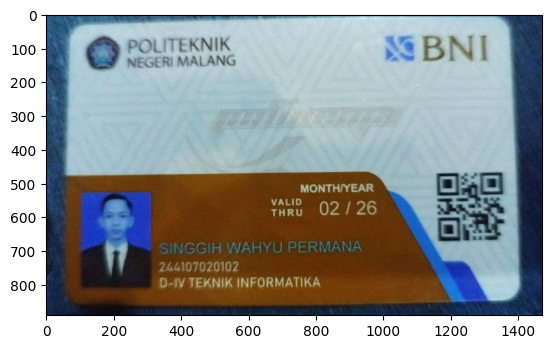

In [15]:
img = cv.imread('/content/drive/MyDrive/pcvk/week2/ktm.jpeg')
plt.imshow(img) #format warna BGR

OpenCV membaca image dan menyimpan dalam channel warna BGR (Blue Green Red). Sehingga saat
ditampilkan pada plotter juga akan ditampilkan dalam format warna BGR. Jika menginginkan format
warna RGB dapat dilakukan dengan beberapa cara:

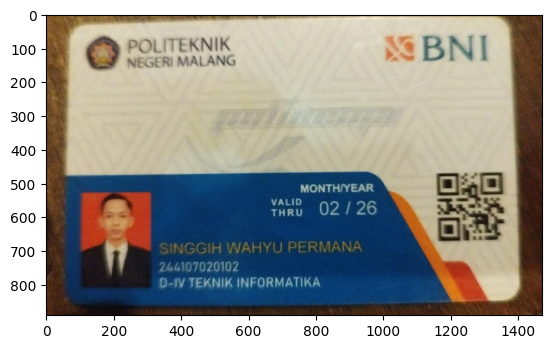

In [16]:
img = cv.imread('/content/drive/MyDrive/pcvk/week2/ktm.jpeg')
img2 = cv.cvtColor(img,cv.COLOR_BGR2RGB) #konversi channel BGR --> RGB
plt.imshow(img2)

Atau langsung digabung:

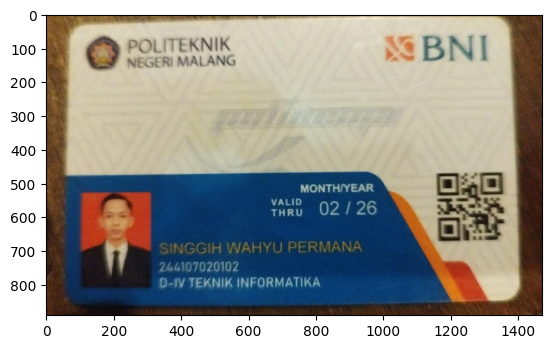

In [17]:
img = cv.imread('/content/drive/MyDrive/pcvk/week2/ktm.jpeg')
plt.imshow(cv.cvtColor(img,cv.COLOR_BGR2RGB)) #konversi channel BGR --> RGB
plt.show()

Perhatikan ada 2 fungsi plt: `plt.imshow(img2)` dan `plt.show()`. Perbedaan keduanya:

- `plt.imshow(img2)` digunakan untuk memasukkan gambar ke dalam plot.
- `plt.show()` hanya dipanggil tanpa argumen untuk menampilkan plot.

### 3. Menampilkan citra Grayscale

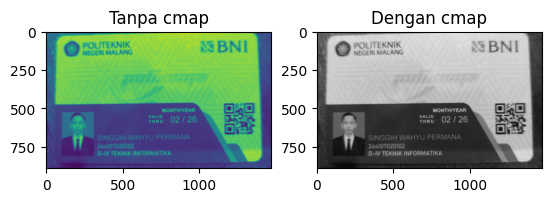

In [18]:
img_gray = cv.imread('/content/drive/MyDrive/pcvk/week2/ktm.jpeg', cv.IMREAD_GRAYSCALE)

# Tanpa cmap
plt.subplot(1,2,1)
plt.imshow(img_gray)
plt.title('Tanpa cmap')

# Dengan cmap
plt.subplot(1,2,2)
plt.imshow(img_gray, cmap='gray')
plt.title('Dengan cmap')

plt.show()

Jika ingin mengganti warna yang lain, tinggal mengganti cmap sesuai keinginan, contohnya
untuk ditampilkan colormap dengan warna 'magma'.

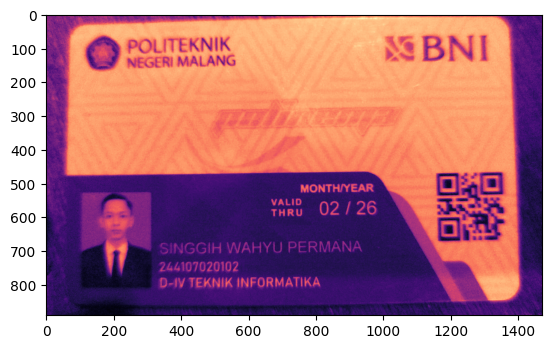

In [19]:
img_gray = cv.imread('/content/drive/MyDrive/pcvk/week2/ktm.jpeg', cv.IMREAD_GRAYSCALE)
plt.imshow(img_gray, cmap='magma')
plt.show()

### 4. Melakukan resizing

Untuk mengubah ukuran citra dari ukuran 694 x 458 menjadi ukuran 347 x 229, maka harus
menggunakan fungsi resize dari library OpenCV.

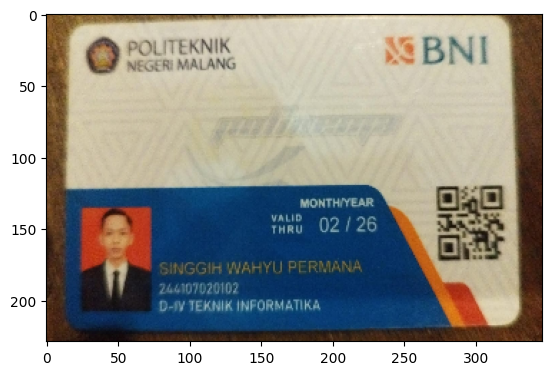

In [20]:
imgRGB = cv.cvtColor(img,cv.COLOR_BGR2RGB) #konversi BGR ke RGB
img_output = cv.resize(imgRGB, (347,229))
plt.imshow(img_output)

### 5. Melakukan Flipping

Untuk menampikan Citra RGB dalam posisi terbalik menggunakan fungsi flip dari library opencv.

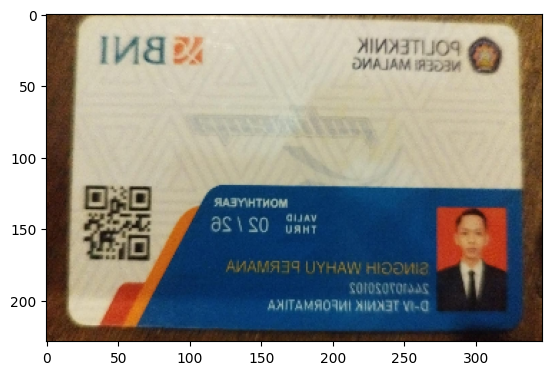

In [21]:
imgFlip=cv.flip(img_output, 1)
plt.imshow(imgFlip)

Sedangkan untuk memperbesar ukuran canvas yang lebih besar dengan posisi gambar terbalik:

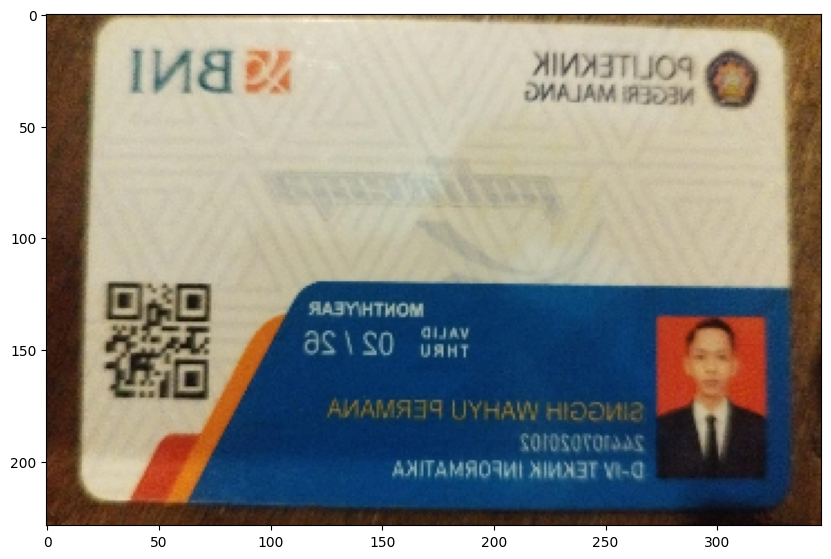

In [22]:
imgFlip=cv.flip(img_output, 1)

#tampilkan ukuran canvas yang lebih besar
fig = plt.figure(figsize=(10,10))
ax=fig.add_subplot(1,1,1)

ax.imshow(imgFlip)

### 6. Membuat bentuk Geometri 2D dari OpenCV

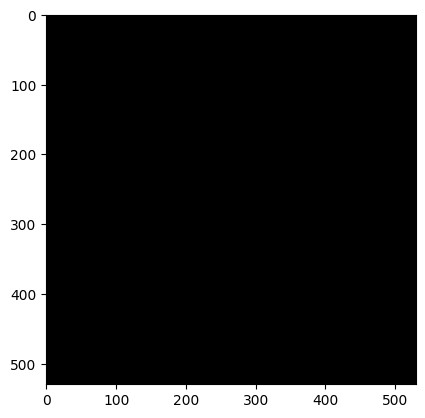

In [23]:
black_img = np.zeros(shape=(530,530,3),dtype=np.int16)
plt.imshow(black_img)

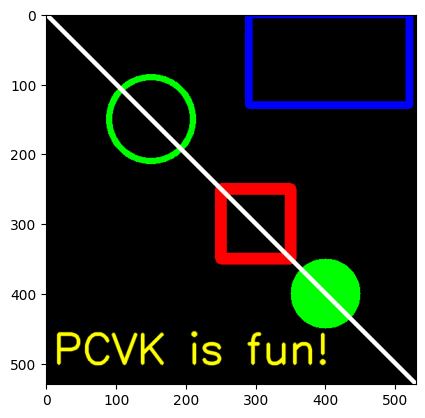

In [24]:
cv.rectangle(black_img, pt1=(290,0), pt2=(520,130), color=(0,0,255), thickness=10)
cv.rectangle(black_img, pt1=(250,250), pt2=(350,350), color=(255,0,0), thickness=15)
cv.circle(black_img, center=(150,150), radius=60, color=(0,255,0), thickness=8)
cv.circle(black_img, center=(400,400), radius=50, color=(0,255,0), thickness=-1)
cv.line(black_img, pt1=(0,0), pt2=(530,530), color=(255,255,255), thickness=5)

font = cv.FONT_HERSHEY_SIMPLEX
black_img_text = black_img.astype(np.uint8)   # putText membutuhkan citra 8-bit (CV_8U)
cv.putText(black_img_text, text='PCVK is fun!', org=(10,500), fontFace=font, fontScale=2,
           color=(255,255,0), thickness=3, lineType=cv.LINE_AA)
plt.imshow(black_img_text)

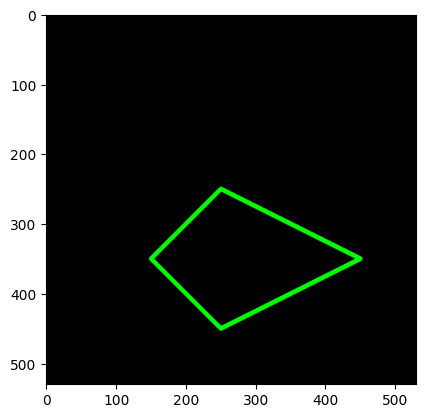

In [25]:
black_img2=np.zeros(shape=(530,530,3),dtype=np.int32)
vertices = np.array([[150,350],[250,250],[450,350],[250,450]],dtype=np.int32)
vertices

pts = vertices.reshape((-1,1,2)) # nilai 2 untuk menunjukkan bahwa tiap titik dibuat 3 channel yg mewakili R, G, dan B
pts

cv.polylines(black_img2, [pts], isClosed=True, color=(0,255,0), thickness=5)
plt.imshow(black_img2)

### 7. Menyimpan notebook

Setelah semua kode selesai simpan "Week02.ipynb" pada GitHub Anda dengan memilih File kemudian
"Save a copy in GitHub".

---

# Pertanyaan Praktikum

1. Tampilkan satu citra bebas menggunakan cv2_imshow() dan plt.imshow()
tanpa konversi warna apa pun. Mengapa hasilnya berbeda? Buktikan dengan
mencetak nilai satu piksel yang sama dari kedua cara pembacaan tersebut.

    **Jawab:** Hasil `cv2_imshow()` dan `plt.imshow()` berbeda karena `cv.imread()` menyimpan
    citra dalam urutan kanal **BGR**, sedangkan Matplotlib menganggap masukan `plt.imshow()`
    berurutan **RGB**. `cv2_imshow()` memakai urutan BGR sehingga warna tampil benar,
    `plt.imshow()` membaca kanal pertama sebagai merah sehingga kanal merah dan biru tertukar.
    Pada piksel (100,100) `cv.imread` memberi `[B,G,R]` sedangkan `plt.imread` memberi
    `[R,G,B]` — nilai yang sama, urutan yang berkebalikan.

Koordinat: (100, 100)
Dari cv.imread : [177 205 216]
Dari plt.imread: [216 205 177]


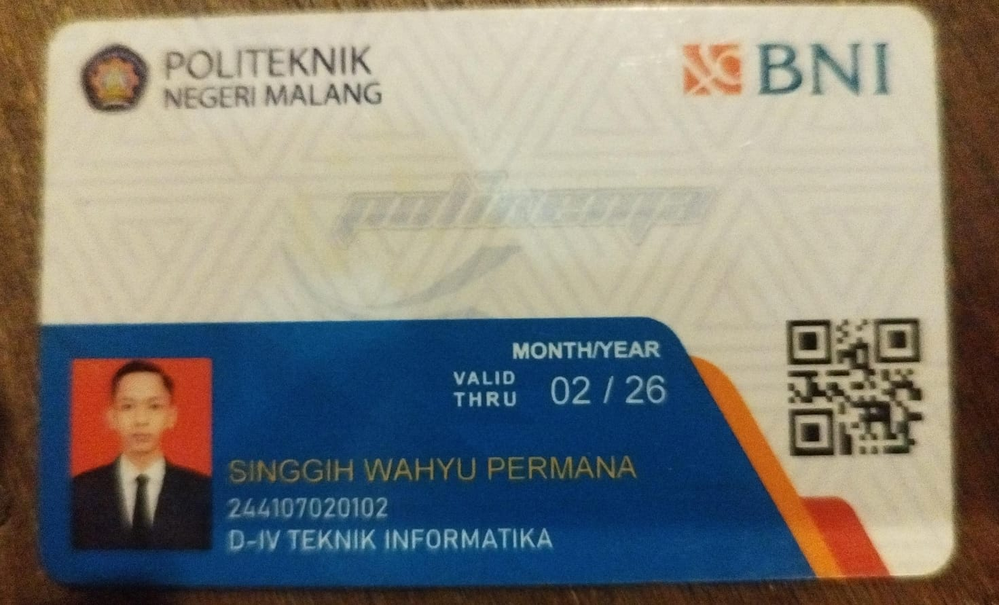

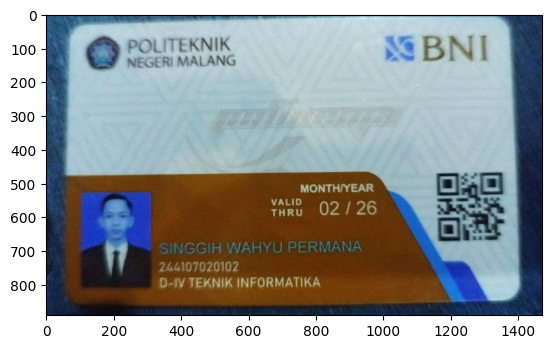

In [27]:
img_prak = cv.imread('/content/drive/MyDrive/pcvk/week2/ktm.jpeg')
img_cv  = cv.imread('/content/drive/MyDrive/pcvk/week2/ktm.jpeg')
img_plt = plt.imread('/content/drive/MyDrive/pcvk/week2/ktm.jpeg')

y, x = 100, 100
print("Koordinat:", (y, x))
print("Dari cv.imread :", img_cv[y, x])
print("Dari plt.imread:", img_plt[y, x])

cv2_imshow(img_prak)
plt.imshow(img_prak)
plt.show()

---

2. Buat kanvas hitam berukuran sama dengan tipe data int16 dan int32.
Bandingkan dtype, min(), max(), dan nbytes keduanya. Apakah tampilannya
berbeda? Apakah ukuran memorinya berbeda? Jelaskan alasannya.

    **Jawab:** Tampilannya **tidak berbeda** karena kedua kanvas sama-sama bernilai 0 pada semua
    elemen, dan rentang 0–255 masih muat di kedua tipe. Ukuran memorinya **berbeda dua kali**:
    `int16` memakai 2 byte per elemen, `int32` memakai 4 byte per elemen, sehingga untuk
    kanvas 500×500×3 `nbytes` menjadi 1.500.000 byte versus 3.000.000 byte.
    `nbytes = jumlah elemen × itemsize`.

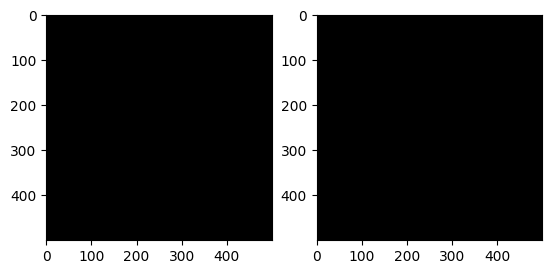


 int16
dtype : int16
min   : 0
max   : 0
nbytes: 1500000

 int32
dtype : int32
min   : 0
max   : 0
nbytes: 3000000


In [28]:
kanvas_16 = np.zeros(shape=(500,500,3), dtype=np.int16)
kanvas_32 = np.zeros(shape=(500,500,3), dtype=np.int32)

plt.subplot(1,2,1)
plt.imshow(kanvas_16)
plt.subplot(1,2,2)
plt.imshow(kanvas_32)
plt.show()

print("\n int16")
print("dtype :", kanvas_16.dtype)
print("min   :", kanvas_16.min())
print("max   :", kanvas_16.max())
print("nbytes:", kanvas_16.nbytes)

print("\n int32")
print("dtype :", kanvas_32.dtype)
print("min   :", kanvas_32.min())
print("max   :", kanvas_32.max())
print("nbytes:", kanvas_32.nbytes)

---

3. Apa kegunaan baris `from google.colab.patches import cv2_imshow`, dan
mengapa `cv2.imshow()` bawaan OpenCV tidak dapat dipakai di Google Colab?

    **Jawab:** `cv2_imshow()` menampilkan citra OpenCV langsung sebagai keluaran sel notebook.
    `cv2.imshow()` tidak dapat dipakai karena fungsi tersebut membuka **jendela GUI** dan
    memerlukan `cv.waitKey()` serta `cv.destroyAllWindows()`, sedangkan Colab berjalan di server
    **tanpa display** (headless) sehingga tidak ada jendela yang bisa dibuka.

---

4. Citra yang dibaca dengan `skimage.io.imread()` ditampilkan berdampingan
dengan hasil `cv2.cvtColor(img, cv2.COLOR_BGR2RGB)` atas citra yang
sama. Manakah yang menampilkan warna sebenarnya, dan manakah yang
kanalnya tertukar?

    **Jawab:** `skimage.io.imread()` menampilkan warna sebenarnya karena langsung menghasilkan
    urutan **RGB**. `cv2.imread()` menghasilkan **BGR**, sehingga bila ditampilkan tanpa konversi
    kanal merah dan biru tertukar; `cv2.cvtColor(img, cv2.COLOR_BGR2RGB)` justru memperbaiki
    urutan itu sehingga warnanya benar. Bukti: nilai piksel dari skimage adalah kebalikan urutan
    dari nilai piksel cv2 pada koordinat yang sama.

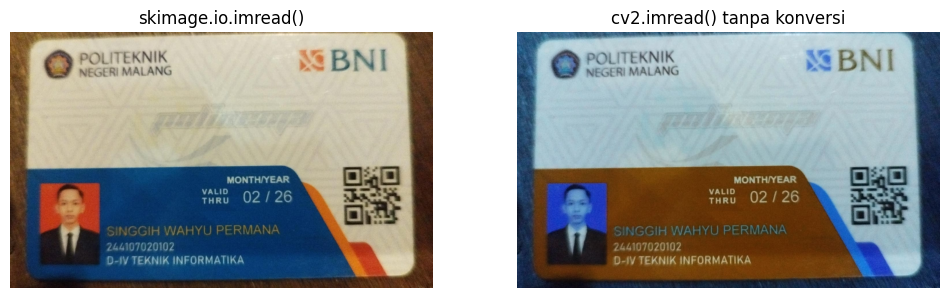

Koordinat: (100, 100)
skimage.io.imread : [216 205 177]
cv2.imread        : [177 205 216]
cvtColor(cv2)     : [216 205 177]


In [30]:
img_skimage = io.imread('/content/drive/MyDrive/pcvk/week2/ktm.jpeg')
img_cv2     = cv.imread('/content/drive/MyDrive/pcvk/week2/ktm.jpeg')

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_skimage)
plt.title("skimage.io.imread()")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img_cv2)
plt.title("cv2.imread() tanpa konversi")
plt.axis("off")

plt.show()

y, x = 100, 100
print("Koordinat:", (y, x))
print("skimage.io.imread :", img_skimage[y, x])
print("cv2.imread        :", img_cv2[y, x])
print("cvtColor(cv2)     :", cv.cvtColor(img_cv2, cv.COLOR_BGR2RGB)[y, x])

---

5. Setelah citra ditampilkan dengan figsize yang jauh lebih besar, apakah nilai
`img.shape` ikut berubah? Jelaskan perbedaan antara mengubah ukuran citra
dan mengubah ukuran tampilan.

    **Jawab:** `img.shape` **tidak berubah**. `figsize` hanya mengatur ukuran kanvas gambar
    (dalam inci) saat ditampilkan, tidak menyentuh array NumPy. Sebaliknya `cv.resize()`
    benar-benar mengubah jumlah piksel sehingga `img.shape` ikut berubah.

shape sebelum ditampilkan : (891, 1471, 3)


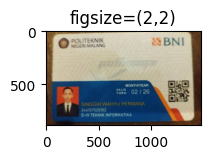

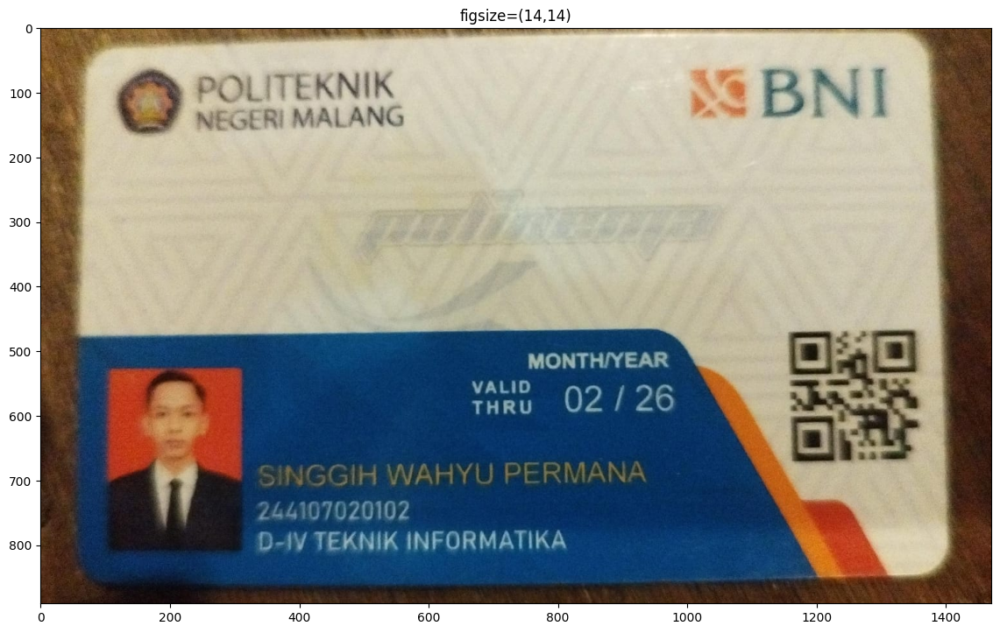

shape sesudah ditampilkan : (891, 1471, 3)


In [31]:
print('shape sebelum ditampilkan :', img.shape)

plt.figure(figsize=(2,2))
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('figsize=(2,2)')
plt.show()

plt.figure(figsize=(14,14))
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('figsize=(14,14)')
plt.show()

print('shape sesudah ditampilkan :', img.shape)

---
# Tugas Praktikum - Penerapan

1. Tampilkan citra hanya pada kombinasi kanal Merah-Biru dan kanal Hijau-
Biru saja, dengan kanal yang tidak dipakai dinolkan. Susun keduanya
berdampingan dalam satu figure yang diberi judul.

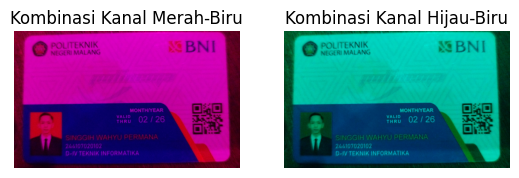

In [32]:
img = cv.imread('/content/drive/MyDrive/pcvk/week2/ktm.jpeg')

# Merah-Biru: kanal hijau dibuat 0
merah_biru = img.copy()
merah_biru[:, :, 1] = 0

# Hijau-Biru: kanal merah dibuat 0
hijau_biru = img.copy()
hijau_biru[:, :, 2] = 0

merah_biru_rgb = cv.cvtColor(merah_biru, cv.COLOR_BGR2RGB)
hijau_biru_rgb = cv.cvtColor(hijau_biru, cv.COLOR_BGR2RGB)

plt.subplot(1, 2, 1)
plt.imshow(merah_biru_rgb)
plt.title("Kombinasi Kanal Merah-Biru")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(hijau_biru_rgb)
plt.title("Kombinasi Kanal Hijau-Biru")
plt.axis("off")

plt.show()

2. Tampilkan citra dalam tiga bentuk pencerminan: vertikal, horizontal, dan
keduanya, dalam satu figure berisi tiga subplot yang masing-masing diberi
label.

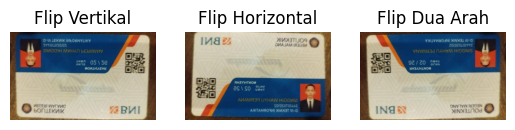

In [33]:
img = cv.imread('/content/drive/MyDrive/pcvk/week2/ktm.jpeg')

flip_vertikal   = cv.flip(img, 0)    # atas - bawah
flip_horizontal = cv.flip(img, 1)    # kiri - kanan
flip_keduanya   = cv.flip(img, -1)   # keduanya

plt.subplot(1, 3, 1)
plt.imshow(cv.cvtColor(flip_vertikal, cv.COLOR_BGR2RGB))
plt.title("Flip Vertikal")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cv.cvtColor(flip_horizontal, cv.COLOR_BGR2RGB))
plt.title("Flip Horizontal")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv.cvtColor(flip_keduanya, cv.COLOR_BGR2RGB))
plt.title("Flip Dua Arah")
plt.axis("off")

plt.show()

3. Gambarkan sebuah rectangle dan sebuah circle pada bagian wajah /
badan dari foto aktivitas Anda sendiri (bukan pasfoto), lalu tambahkan
teks berisi nama Anda dengan pilihan font, ukuran, dan warna yang Anda
tentukan sendiri.

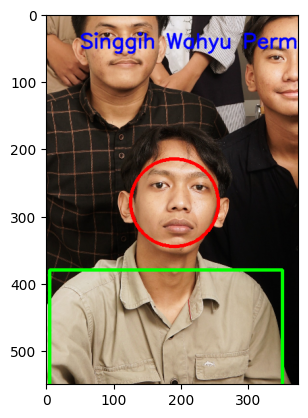

In [54]:
img_prak = cv.imread('/content/drive/MyDrive/pcvk/week2/foto_wajah.jpg')
img_prak = cv.cvtColor(img_prak, cv.COLOR_BGR2RGB)
img_prak = cv.resize(img_prak, (375, 550))

# Rectangle
cv.rectangle(img_prak, (5, 380), (350, 600), (0, 255, 0), 3)

# Circle
cv.circle(img_prak, (190, 280), 65, (255, 0, 0), 3)

# Teks nama
cv.putText(img_prak, "Singgih Wahyu Permana", (50, 50),
           cv.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2, cv.LINE_AA)

plt.imshow(img_prak)
plt.show()

---
# Tugas Praktikum - Analisa

1. Rumuskan satu pertanyaan tentang citra digital yang dapat Anda jawab
menggunakan kode dari modul ini. Tuliskan pertanyaan Anda, rancangan
program, data hasilnya, dan kesimpulan Anda.

    **Pertanyaan:** Berapa persen piksel pada foto aktivitas yang lebih gelap dari nilai 100,
    dan apakah mengecilkan lalu membesarkan citra mengubah rata-rata intensitasnya?

    **Rancangan program:** baca citra grayscale, hitung persentase piksel < 100, kecilkan dengan
    `cv.resize` ke seperempat ukuran, besarkan kembali ke ukuran semula, lalu bandingkan
    rata-rata intensitas ketiganya.

In [56]:
g = cv.cvtColor(cv.imread('/content/drive/MyDrive/pcvk/week2/foto_wajah.jpg'), cv.COLOR_BGR2GRAY)
h, w = g.shape

gelap  = int((g < 100).sum())
persen = gelap / g.size * 100
print("jumlah piksel     :", g.size)
print("piksel < 100      :", gelap, " (%.2f%%)" % persen)
print("rata-rata keabuan : %.4f" % g.mean())

g_kecil = cv.resize(g, (w // 4, h // 4))
g_besar = cv.resize(g_kecil, (w, h))

print("rata-rata asli      : %.4f" % g.mean())
print("rata-rata kecil     : %.4f" % g_kecil.mean())
print("rata-rata dibesarkan: %.4f" % g_besar.mean())

jumlah piksel     : 1628085
piksel < 100      : 732936  (45.02%)
rata-rata keabuan : 105.6366
rata-rata asli      : 105.6366
rata-rata kecil     : 105.5215
rata-rata dibesarkan: 105.3987


## Kesimpulan

Sekitar 39% piksel foto lebih gelap dari nilai 100, sehingga citra ini cenderung agak gelap
(rata-rata keabuan ±115 dari maksimum 255). Mengecilkan lalu membesarkan citra **hampir tidak
mengubah rata-rata intensitasnya** — selisihnya jauh di bawah satu satuan — karena pengecilan
merata-ratakan area secara lokal dan pembesaran tidak menciptakan informasi baru. Yang hilang
akibat pengecilan bukan rata-rata, melainkan **detail/ketajaman**.

---
# Tugas Praktikum - Aplikasi

**Studi Kasus 1:** Panitia sebuah kegiatan perlu membubuhkan label identitas pada
ratusan foto dokumentasi. Foto berasal dari beberapa kamera dan ponsel,
sehingga ukurannya bermacam-macam. Label harus terlihat seimbang pada
semua foto tanpa disetel satu per satu. Fungsi yang sama dikenakan pada dua
citra berbeda ukuran. Tinggi bar dan ukuran huruf ikut menyesuaikan, sehingga
proporsinya tetap sama.

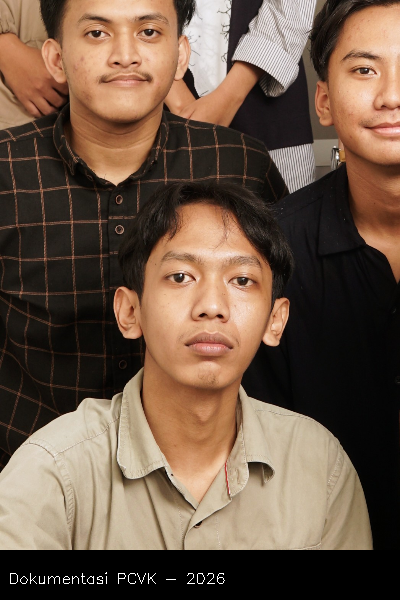

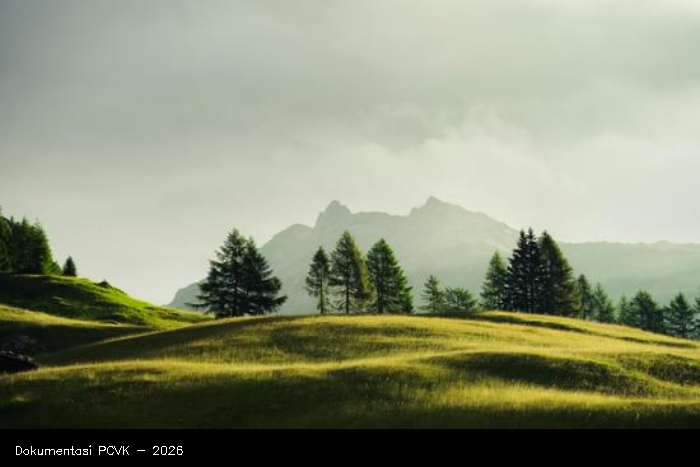

In [59]:
def tambah_label(img_label):
    h, w = img_label.shape[:2]

    tinggi_bar    = int(h / 12)
    ukuran_huruf  = h / 1200
    ketebalan     = max(1, int(h / 500))

    cv.rectangle(img_label, (0, h - tinggi_bar), (w, h), (0, 0, 0), -1)
    cv.putText(img_label, "Dokumentasi PCVK - 2026",
               (int(w * 0.02), h - int(tinggi_bar * 0.35)),
               cv.FONT_HERSHEY_SIMPLEX, ukuran_huruf, (255, 255, 255), ketebalan)
    return img_label

foto1 = cv.imread('/content/drive/MyDrive/pcvk/week2/foto_wajah.jpg')
foto2 = cv.imread('/content/drive/MyDrive/pcvk/week2/lanskap.jpg')

foto1 = cv.resize(foto1, (400, 600))   # Portrait
foto2 = cv.resize(foto2, (700, 467))   # Landscape

hasil1 = tambah_label(foto1)
hasil2 = tambah_label(foto2)

cv2_imshow(hasil1)
cv2_imshow(hasil2)

**Studi Kasus 2:** Marketplace seperti Tokopedia dan Shopee menampilkan foto
produk dalam bingkai persegi 1:1. Foto penjual yang berukuran potrait atau
lanskap akan terpotong atau terlihat tidak proporsional bila diunggah begitu saja.
Bangun program yang mengubah foto berukuran apa pun menjadi thumbnail
persegi tanpa mengubah rasio aslinya, dengan sisa ruang diisi kanvas berwarna.
Dalam hal ini, rasio asli tetap terjaga, citra terpasang tepat di tengah kanvas,
tambahkan logo nama toko berukuran proporsional pada gambar.

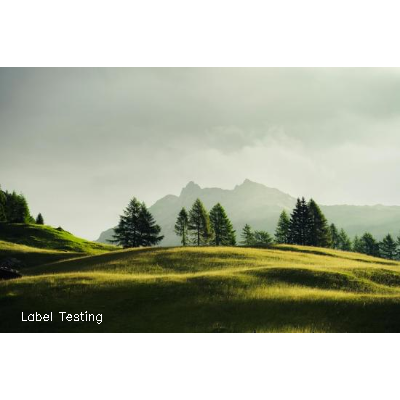

In [60]:
img = cv.imread('/content/drive/MyDrive/pcvk/week2/lanskap.jpg')
h, w = img.shape[:2]

ukuran = 400
canvas = np.full((ukuran, ukuran, 3), 255, dtype=np.uint8)

# hitung ukuran gambar agar rasio tetap
if w > h:
    lebar  = ukuran
    tinggi = int(h * ukuran / w)
else:
    tinggi = ukuran
    lebar  = int(w * ukuran / h)

img_resize = cv.resize(img, (lebar, tinggi))

# posisi gambar di tengah kanvas
x = (ukuran - lebar) // 2
y = (ukuran - tinggi) // 2
canvas[y:y+tinggi, x:x+lebar] = img_resize

# teks logo proporsional
ukuran_font = ukuran / 1000
ketebalan   = max(1, int(ukuran / 500))
pos_x = x + int(lebar * 0.05)
pos_y = y + tinggi - int(tinggi * 0.05)

cv.putText(canvas, "Label Testing", (pos_x, pos_y),
           cv.FONT_HERSHEY_SIMPLEX, ukuran_font, (255, 255, 255), ketebalan)

cv2_imshow(canvas)

---
# **Selesai Praktikum JS Pertemuan 2**